# Thời gian, hình học và phân cụm DIALOG

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Audit Dialog Timeline

Nguồn: `src/scripts/audit_dialog_timeline.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/audit_dialog_timeline.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Audit observed (anonymized) dialogue calendar, without inferring real dates.

Run from repository root: .venv/Scripts/python.exe src/scripts/audit_dialog_timeline.py
"""
from pathlib import Path
import json
import duckdb
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

OUT = Path('outputs/dialog_temporal_audit')
OUT.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
events = con.execute("SELECT client_id,event_time,fold FROM read_parquet('data/MBD-mini/detail/dialog/**/*.parquet', hive_partitioning=true)").df()
con.close()
events['event_time'] = pd.to_datetime(events.event_time)
assert events.event_time.notna().all()
events['date'] = events.event_time.dt.normalize()
calendar = pd.date_range(events.date.min(), events.date.max(), freq='D')
daily = events.groupby('date').agg(dialogs=('client_id','size'), clients=('client_id','nunique')).reindex(calendar, fill_value=0)
daily.index.name = 'date'
daily['mean_7d'] = daily.dialogs.rolling(7, min_periods=7).mean()
daily['mean_28d'] = daily.dialogs.rolling(28, min_periods=28).mean()
daily.to_csv(OUT/'daily.csv')
# Exclude the partial starting month from calendar-day exposure comparisons.
full = daily.loc['2021-03-01':].copy()
full['weekday'] = full.index.day_of_week
weekday = full.groupby('weekday').agg(calendar_days=('dialogs','size'), dialogs=('dialogs','sum'), dialogs_per_day=('dialogs','mean'))
weekday.to_csv(OUT/'weekday_normalized.csv')
monthly = daily.resample('MS').agg(dialogs=('dialogs','sum'), observed_calendar_days=('dialogs','size'), zero_days=('dialogs',lambda s: (s==0).sum()))
monthly['dialogs_per_day'] = monthly.dialogs / monthly.observed_calendar_days
monthly['rate_change_pct'] = monthly.dialogs_per_day.pct_change()*100
monthly['active_clients'] = events.groupby(events.date.dt.to_period('M')).client_id.nunique().to_numpy()
monthly.to_csv(OUT/'monthly.csv')
fold = events.groupby([events.date.dt.to_period('M'), 'fold']).size().unstack(fill_value=0)
fold.to_csv(OUT/'monthly_by_fold.csv')
comparisons=[]
for cutoff in ['2022-01-01','2022-06-01']:
    t=pd.Timestamp(cutoff)
    before=daily.loc[t-pd.Timedelta(days=28):t-pd.Timedelta(days=1),'dialogs']
    after=daily.loc[t:t+pd.Timedelta(days=27),'dialogs']
    comparisons.append(dict(boundary=cutoff, before_28d_mean=float(before.mean()), after_28d_mean=float(after.mean()), change_pct=float((after.mean()/before.mean()-1)*100)))
weekend=full.loc[full.weekday>=5,'dialogs'].mean()
workday=full.loc[full.weekday<5,'dialogs'].mean()
summary=dict(rows=len(events), clients=int(events.client_id.nunique()), first=str(events.event_time.min()),last=str(events.event_time.max()), calendar_days=len(daily), zero_days=int((daily.dialogs==0).sum()), min_daily=int(daily.dialogs.min()), max_daily=int(daily.dialogs.max()), weekend_per_day=float(weekend), weekday_per_day=float(workday), weekend_weekday_ratio=float(weekend/workday), comparisons=comparisons, source='https://arxiv.org/html/2409.17587v2', interpretation='Dates are anonymized with random noise; original hour preserved. Calendar weekdays and exact real-world breaks are not verified. First month is partial. UTC/local timezone is not verified.')
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'text.color':'#193454','axes.labelcolor':'#193454'})
fig, axes=plt.subplots(3,1,figsize=(13,12),dpi=170,gridspec_kw={'height_ratios':[.8,1.3,1]})
fig.subplots_adjust(left=.09,right=.96,top=.88,bottom=.12,hspace=.48)
fig.suptitle('Kiểm tra lịch thời gian hội thoại',fontsize=24,fontweight='bold',x=.09,ha='left',y=.97)
fig.text(.09,.925,'217.205 hội thoại · Ngày/giờ theo dữ liệu đã ẩn danh · Không quy đổi múi giờ',color='#62738a')
ax=axes[0]
ax.bar(range(7),weekday.dialogs_per_day,color=['#78a6dd']*5+['#368b7c']*2,width=.6)
ax.set_xticks(range(7),['Thứ 2','Thứ 3','Thứ 4','Thứ 5','Thứ 6','Thứ 7','Chủ nhật'])
for i,v in enumerate(weekday.dialogs_per_day): ax.text(i,v+3,f'{v:.1f}',ha='center',fontsize=10)
ax.set_ylim(0,weekday.dialogs_per_day.max()*1.2)
ax.set_ylabel('Hội thoại / ngày')
ax.set_title('Chuẩn hóa theo số ngày từng thứ · 03/2021–12/2022',fontweight='bold')
ax=axes[1]
ax.plot(daily.index,daily.dialogs,color='#b4c8e1',lw=.7,label='Từng ngày')
ax.plot(daily.index,daily.mean_28d,color='#2868b3',lw=2,label='Trung bình 28 ngày (lùi)')
ax.set_ylabel('Hội thoại / ngày'); ax.set_title('Chuỗi ngày đầy đủ · Không có ngày trống trong 690 ngày quan sát',fontweight='bold'); ax.legend(loc='upper left',frameon=False)
ax=axes[2]
ax.plot(monthly.index,monthly.dialogs_per_day,'o-',color='#2868b3',lw=2,ms=4)
ax.set_ylabel('Hội thoại / ngày'); ax.set_title('Trung bình ngày từng tháng · Loại ảnh hưởng tháng dài/ngắn',fontweight='bold')
for ax in axes[1:]:
    ax.axvspan(pd.Timestamp('2022-01-01'),pd.Timestamp('2022-06-01'),color='#edb568',alpha=.15,label='01–05/2022')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
    ax.set_ylim(bottom=0)
for ax in axes:
    ax.grid(axis='y',alpha=.18); ax.set_axisbelow(True)
    for spine in ['top','right']: ax.spines[spine].set_visible(False)
fig.text(.09,.062,'Vùng tô: 01–05/2022. Tháng 02/2021 chỉ có dữ liệu từ 10/02 nên là tháng không đầy đủ.',fontsize=10,color='#62738a')
fig.text(.09,.032,'Nhà phát hành thêm nhiễu vào ngày, giữ giờ gốc: không dùng thứ/ngày này để kết luận lịch làm việc thực tế.',fontsize=10,color='#62738a')
fig.savefig(OUT/'dialog_timeline_audit.png')
plt.close(fig)
print(json.dumps(summary,ensure_ascii=False,indent=2))
print(monthly.loc['2021-12':'2022-06'].to_string())
print(fold.loc['2021-12':'2022-06'].to_string())

{
  "rows": 217205,
  "clients": 46320,
  "first": "2021-02-10 09:36:07.022271",
  "last": "2022-12-31 20:25:11.730797",
  "calendar_days": 690,
  "zero_days": 0,
  "min_daily": 4,
  "max_daily": 516,
  "weekend_per_day": 330.9109947643979,
  "weekday_per_day": 318.98541666666665,
  "weekend_weekday_ratio": 1.0373859664882212,
  "comparisons": [
    {
      "boundary": "2022-01-01",
      "before_28d_mean": 381.2857142857143,
      "after_28d_mean": 168.67857142857142,
      "change_pct": -55.760584488572505
    },
    {
      "boundary": "2022-06-01",
      "before_28d_mean": 186.96428571428572,
      "after_28d_mean": 403.5357142857143,
      "change_pct": 115.83572110792741
    }
  ],
  "source": "https://arxiv.org/html/2409.17587v2",
  "interpretation": "Dates are anonymized with random noise; original hour preserved. Calendar weekdays and exact real-world breaks are not verified. First month is partial. UTC/local timezone is not verified."
}
            dialogs  observed_calendar_

### Kết quả: `src/scripts/audit_dialog_timeline.py`

**outputs/dialog_temporal_audit/dialog_timeline_audit.png**

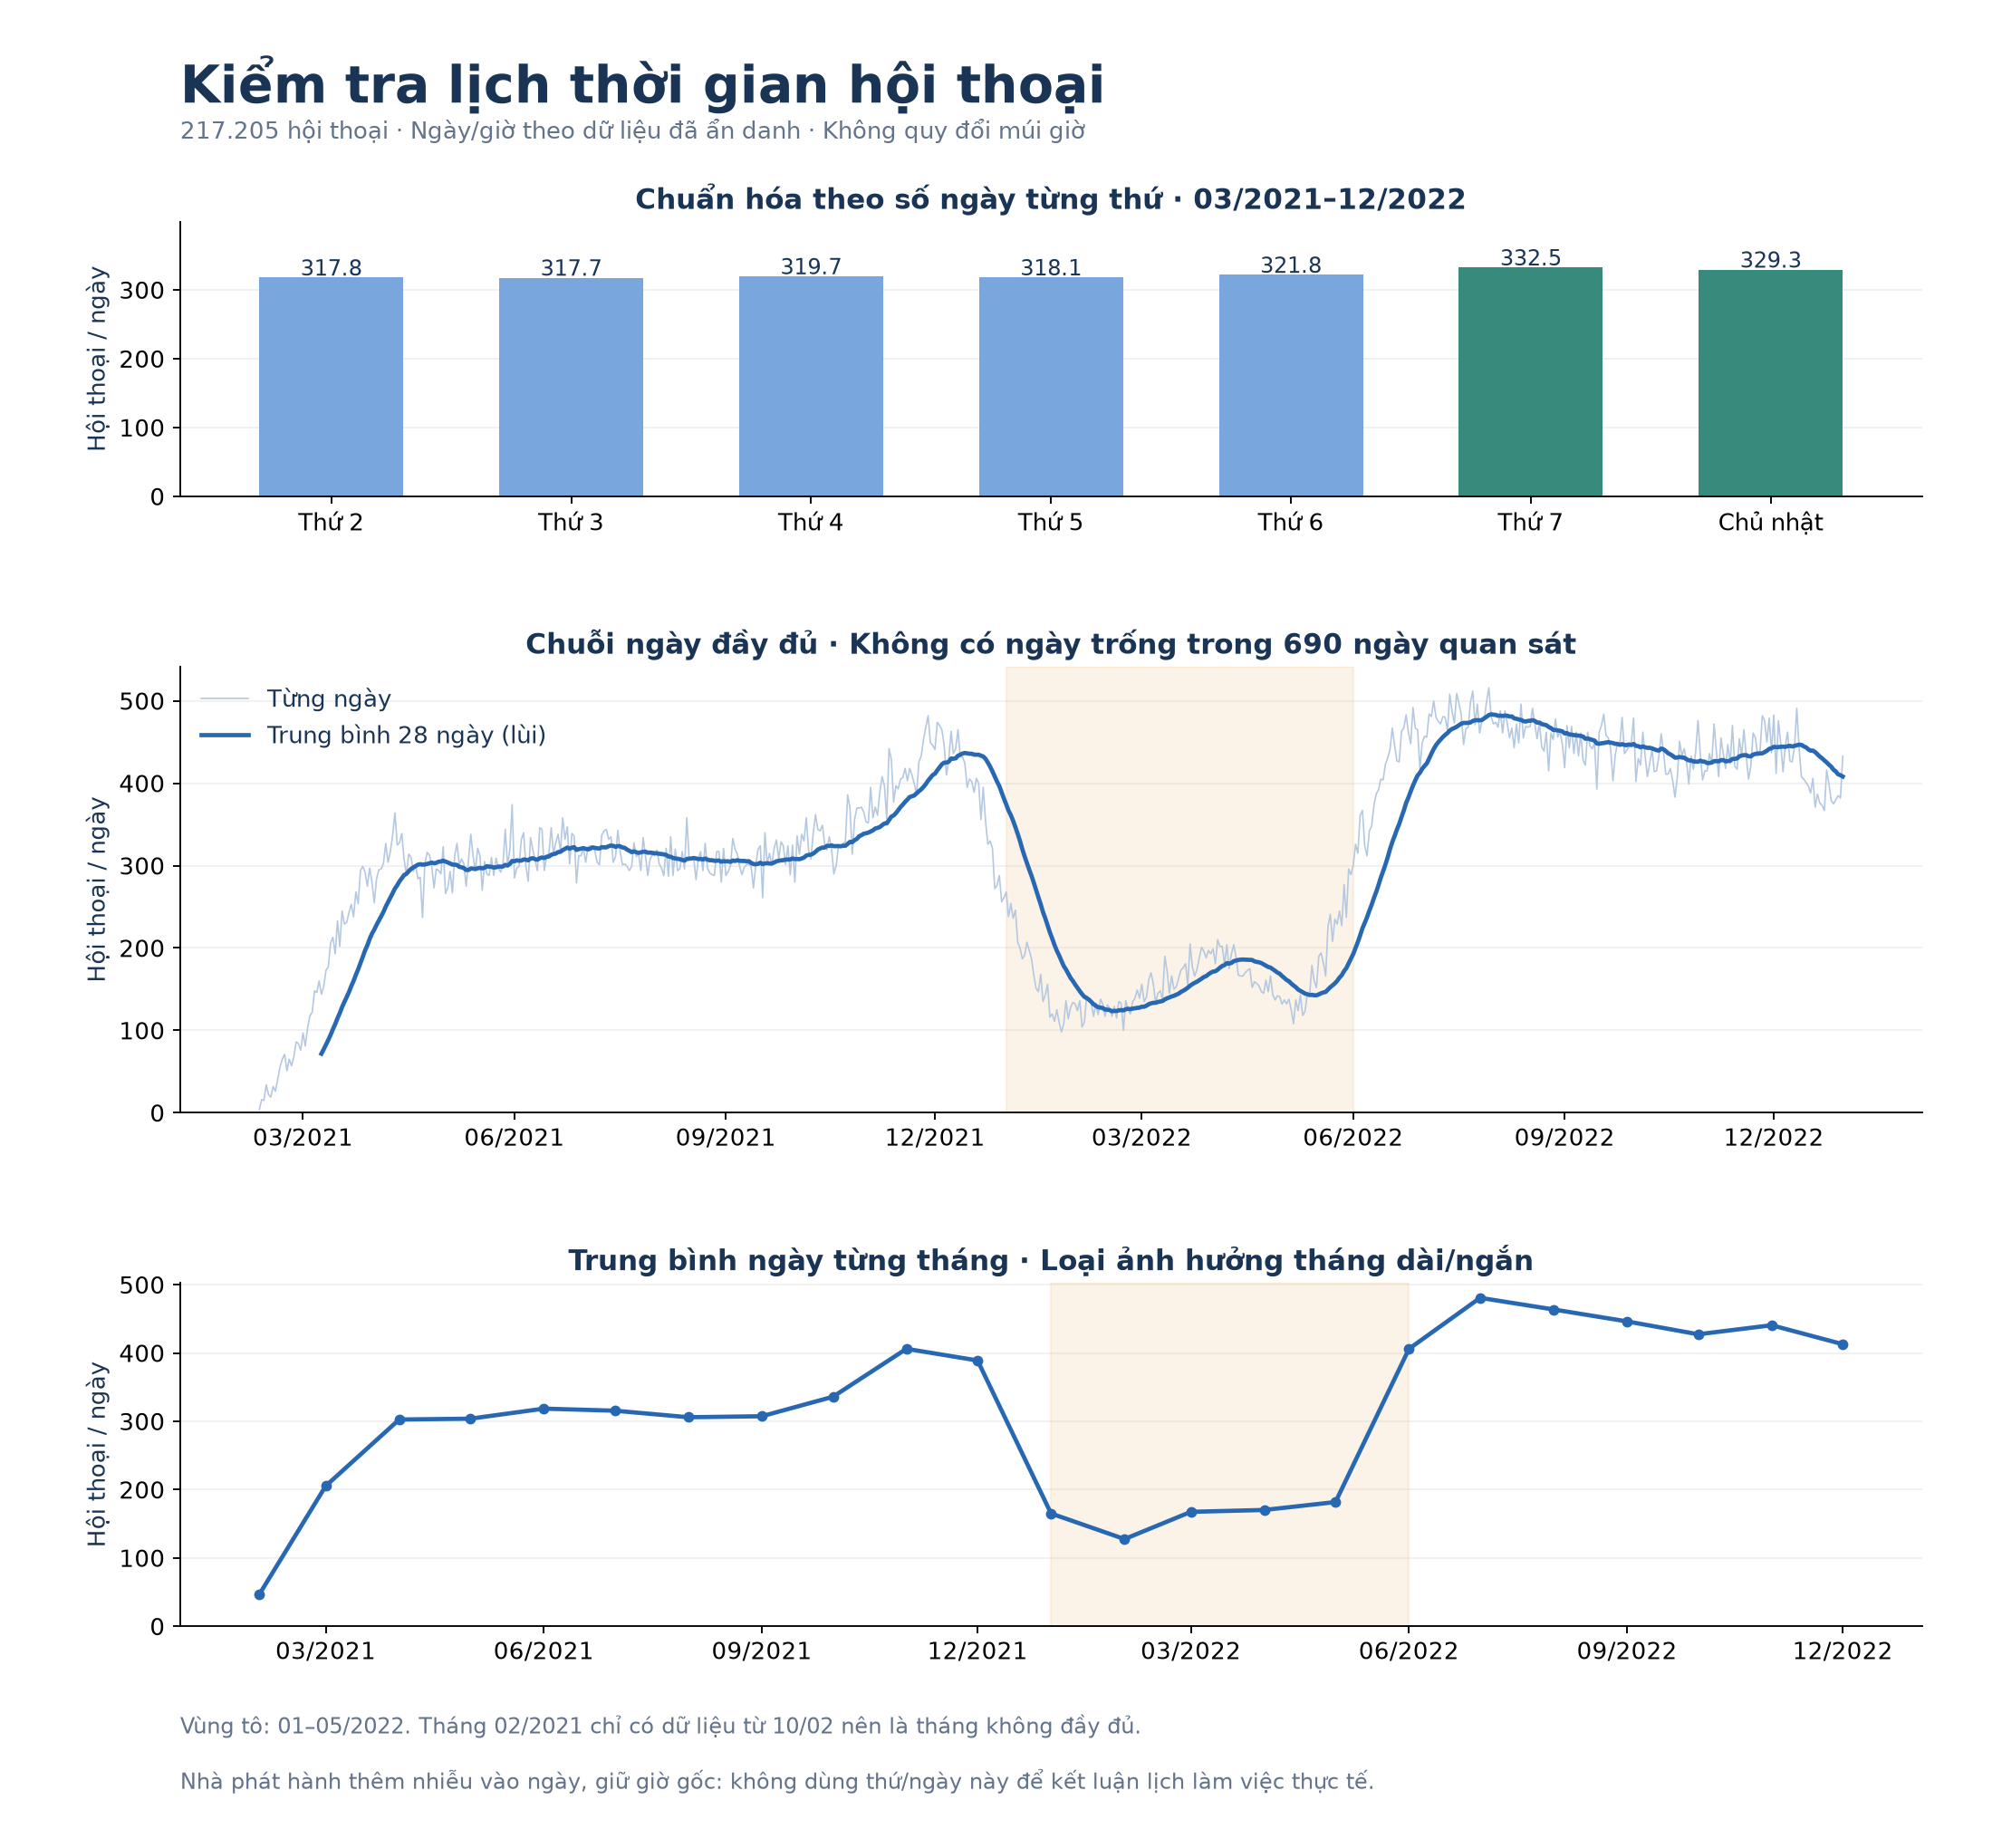

**outputs/dialog_temporal_audit/daily.csv** — 5 dòng đầu

,date,dialogs,clients,mean_7d,mean_28d
0,2021-02-10,4,4,NaN,NaN
1,2021-02-11,16,16,NaN,NaN
2,2021-02-12,15,15,NaN,NaN
3,2021-02-13,34,32,NaN,NaN
4,2021-02-14,22,22,NaN,NaN


**outputs/dialog_temporal_audit/monthly.csv** — 5 dòng đầu

,date,dialogs,observed_calendar_days,zero_days,dialogs_per_day,rate_change_pct,active_clients
0,2021-02-01,888,19,0,46.736842,NaN,772
1,2021-03-01,6367,31,0,205.387097,339.454374,4337
2,2021-04-01,9079,30,0,302.633333,47.347783,5692
3,2021-05-01,9419,31,0,303.838710,0.398296,5830
4,2021-06-01,9557,30,0,318.566667,4.847294,5969


**outputs/dialog_temporal_audit/monthly_by_fold.csv** — 5 dòng đầu

,date,0,1,2,3,4
0,2021-02,182,171,185,171,179
1,2021-03,1284,1267,1303,1278,1235
2,2021-04,1746,1796,1897,1782,1858
3,2021-05,1902,1885,1902,1807,1923
4,2021-06,1990,1934,1941,1829,1863


**outputs/dialog_temporal_audit/weekday_normalized.csv** — 5 dòng đầu

,weekday,calendar_days,dialogs,dialogs_per_day
0,0,96,30508,317.791667
1,1,96,30495,317.656250
2,2,96,30688,319.666667
3,3,96,30533,318.052083
4,4,96,30889,321.760417


File kết quả khác: `outputs/dialog_temporal_audit/summary.json`

In [4]:
show_generated_results(__eda_started_ns, 'src/scripts/audit_dialog_timeline.py')

## Plot Dialog Label Date Transition

Nguồn: `src/scripts/plot_dialog_label_date_transition.py`. Chạy các ô của phần này theo thứ tự.

In [5]:
__file__ = str(ROOT / 'src/scripts/plot_dialog_label_date_transition.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [6]:
"""Full-population source events before/after the recorded label date (Moscow)."""
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path(__file__).resolve().parents[2]
OUT = ROOT / 'outputs/full_population_temporal_eda_20261118'
LABEL = (ROOT / 'data/MBD-mini/targets/**/*.parquet').as_posix()

def plot(source):
    event_path = (ROOT / f'data/MBD-mini/detail/{source}/**/*.parquet').as_posix()
    c = duckdb.connect()
    c.execute("SET memory_limit='3GB'")
    c.execute('SET threads=2')
    c.execute(f"SET temp_directory='{(OUT / ('tmp_' + source + '_transition')).as_posix()}'")
    bounds = c.execute(f"SELECT min(event_time),max(event_time) FROM read_parquet('{event_path}')").fetchone()
    q = c.execute(f"""
        WITH labels AS (
          SELECT client_id, CAST(mon AS DATE) mon,
            greatest(target_1,target_2,target_3,target_4) purchase,
            CAST(mon AS TIMESTAMP) - INTERVAL '3 hours' cutoff_utc
          FROM read_parquet('{LABEL}')
          WHERE greatest(target_1,target_2,target_3,target_4)=1
        ), joined AS (
          SELECT l.client_id,l.mon,l.purchase,l.cutoff_utc,
            count(d.event_time) FILTER (WHERE d.event_time < l.cutoff_utc) n_before,
            count(d.event_time) FILTER (WHERE d.event_time >= l.cutoff_utc) n_after
          FROM labels l LEFT JOIN read_parquet('{event_path}') d
            ON l.client_id=d.client_id
           AND d.event_time >= l.cutoff_utc - INTERVAL '30 days'
           AND d.event_time < l.cutoff_utc + INTERVAL '30 days'
          GROUP BY l.client_id,l.mon,l.purchase,l.cutoff_utc
        )
        SELECT mon,purchase,
          CASE WHEN cutoff_utc - INTERVAL '30 days' < ? OR cutoff_utc + INTERVAL '30 days' > ?
                 THEN 'Chưa đủ quan sát'
               WHEN n_before>0 AND n_after>0 THEN 'Cả trước và sau'
               WHEN n_before>0 THEN 'Chỉ trước'
               WHEN n_after>0 THEN 'Chỉ sau'
               ELSE 'Không có hai phía' END state,
          count(*) customers
        FROM joined GROUP BY 1,2,3 ORDER BY 1,2,3
    """, bounds).df()
    q.to_csv(OUT / f'{source}_label_date_transition_30d.csv', index=False)
    totals = q.groupby(['mon','purchase']).customers.sum().unstack()
    assert len(totals)==12 and totals.sum(axis=1).gt(0).all()
    positive = q[q.purchase.eq(1)].pivot(index='mon',columns='state',values='customers').fillna(0)
    states = ['Không có hai phía','Chỉ trước','Chỉ sau','Cả trước và sau','Chưa đủ quan sát']
    colors = ['#cbd5e1','#2875b9','#db6b28','#7952b3','#94a3b8']
    positive = positive.reindex(columns=states,fill_value=0)
    share = positive.div(positive.sum(axis=1),axis=0)
    fig,ax=plt.subplots(figsize=(13,6))
    bottom = 0
    for state,color in zip(states,colors):
        ax.bar(range(len(share)),share[state],bottom=bottom,label=state,color=color)
        bottom += share[state]
    ax.set_xticks(range(len(share)),[pd.Timestamp(x).strftime('%m/%Y') for x in share.index],rotation=35)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel('Tỷ trọng khách–tháng có mua')
    ax.set_title(f'{source.upper()} quanh ngày ghi nhận nhãn | toàn bộ khách–tháng mua',weight='bold')
    ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
    for i,n in enumerate(positive.sum(axis=1)):
        ax.text(i,1.01,f'n={int(n):,}',rotation=90,ha='center',va='bottom',fontsize=7)
    ax.set_ylim(0,1.2)
    fig.text(.01,.01,'Ranh giới: 00:00 Moscow ngày mon; cửa sổ ±30 ngày. Tháng cuối thiếu log sau mốc được giữ riêng. '
             'Ngày mon không nhất thiết là ngày giao dịch thực tế; raw timestamp giả định UTC.',fontsize=8)
    fig.subplots_adjust(left=.08,right=.76,bottom=.2,top=.85)
    fig.savefig(OUT/f'{source}_label_date_transition_30d.png',dpi=170,bbox_inches='tight')
    fig.savefig(OUT/f'{source}_label_date_transition_30d.svg',bbox_inches='tight')
    print(f'{source}_label_date_transition_30d.png')

if __name__=='__main__':
    for source in ('dialog','geo'):
        plot(source)

dialog_label_date_transition_30d.png


geo_label_date_transition_30d.png


### Kết quả: `src/scripts/plot_dialog_label_date_transition.py`

**outputs/full_population_temporal_eda_20261118/dialog_label_date_transition_30d.png**

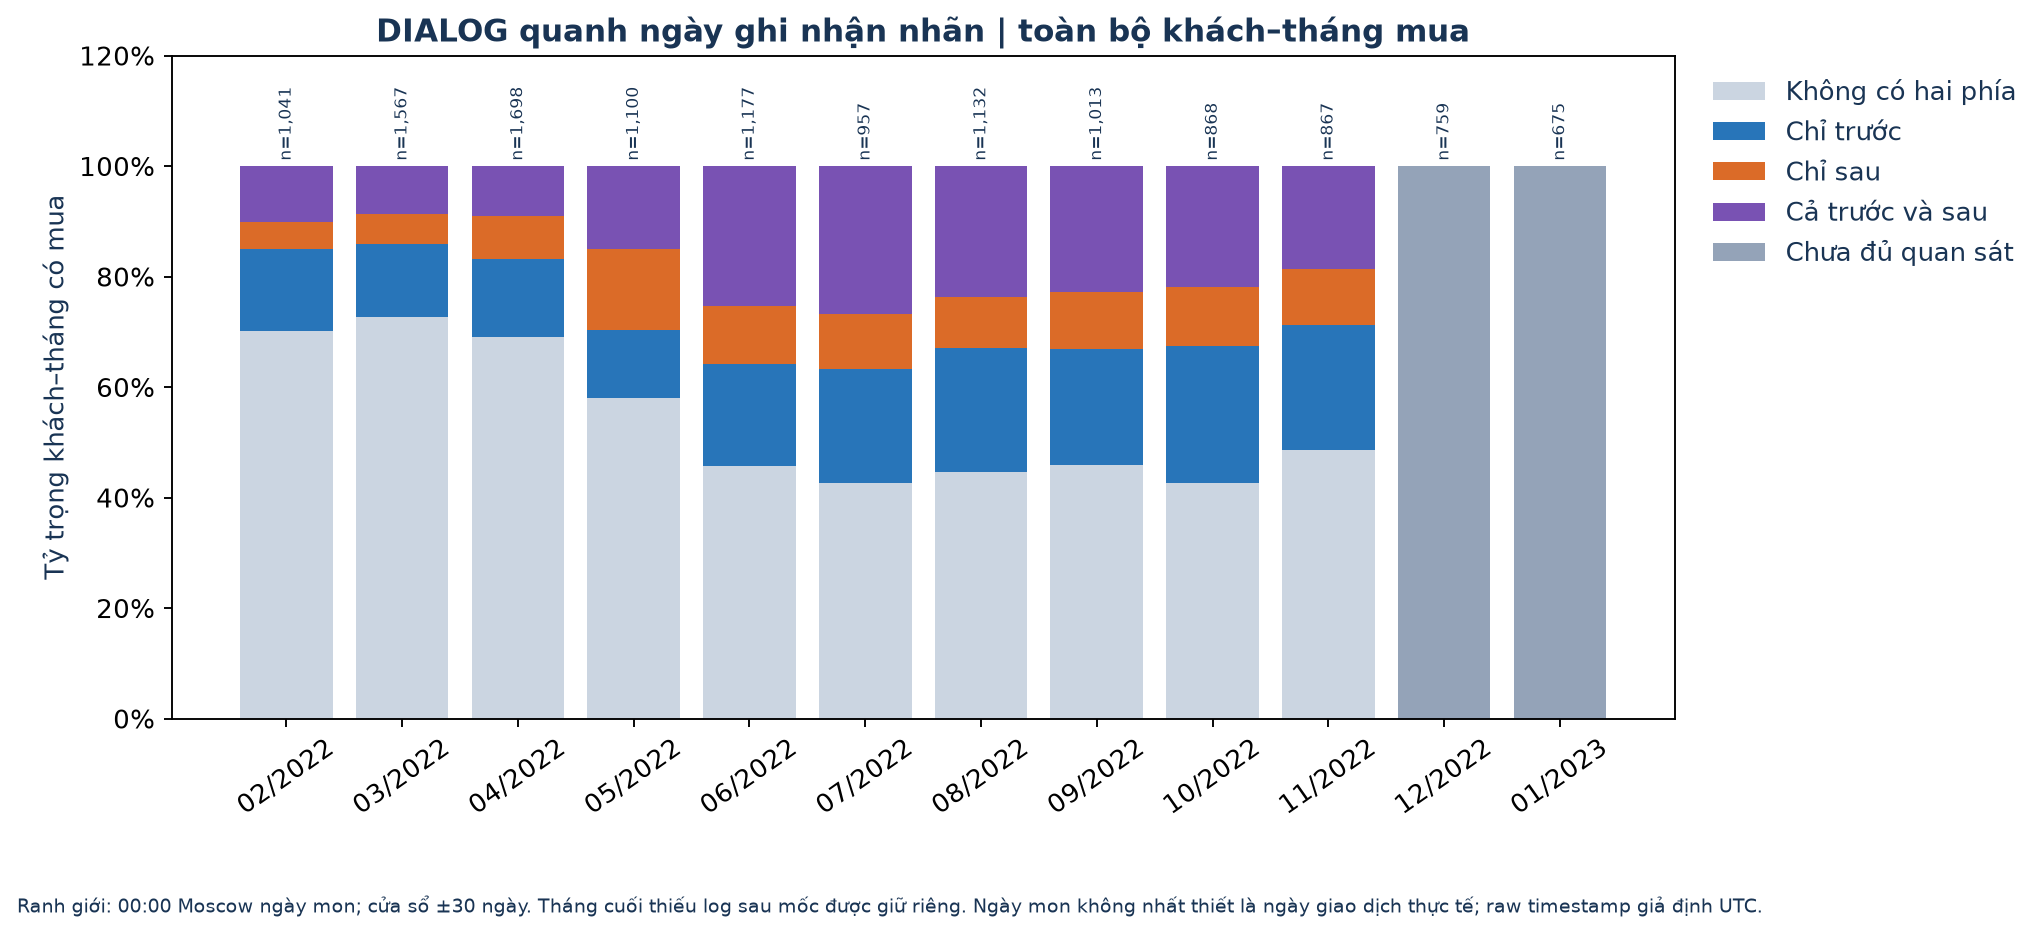

**outputs/full_population_temporal_eda_20261118/geo_label_date_transition_30d.png**

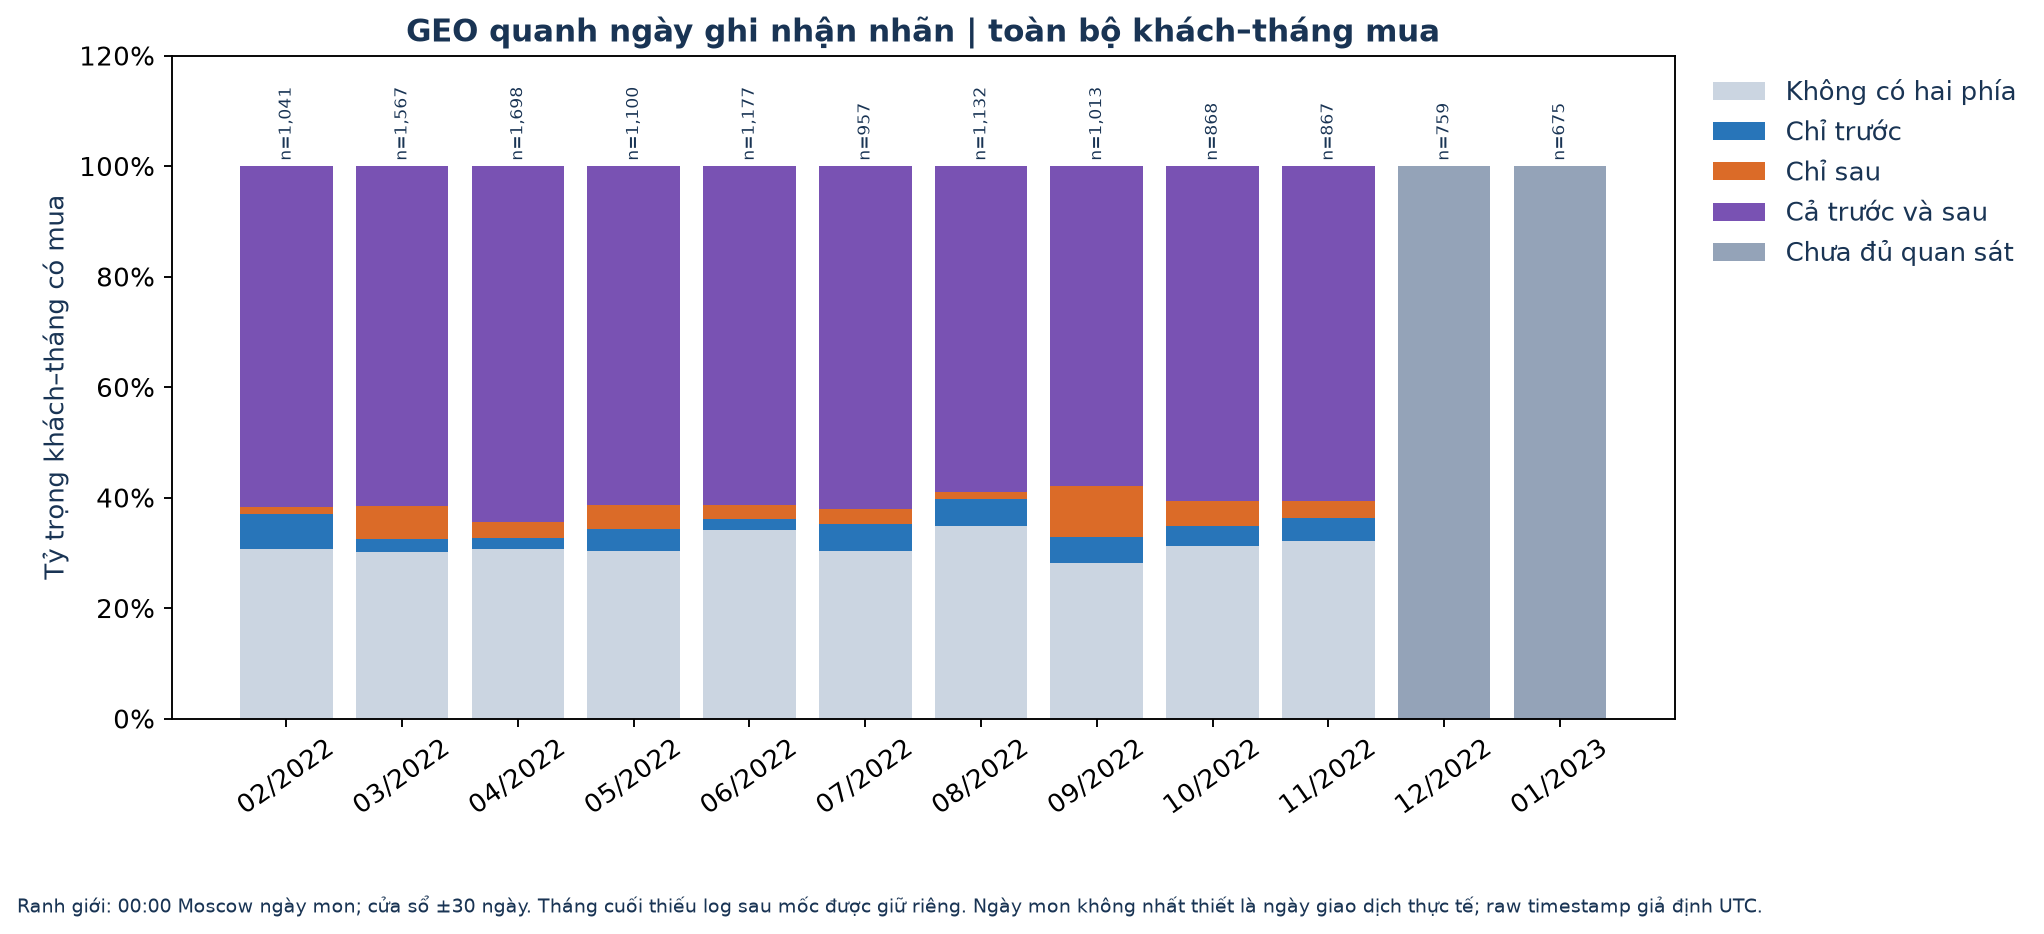

**outputs/full_population_temporal_eda_20261118/dialog_label_date_transition_30d.csv** — 5 dòng đầu

,mon,purchase,state,customers
0,2022-02-28,1,Chỉ sau,51
1,2022-02-28,1,Chỉ trước,153
2,2022-02-28,1,Cả trước và sau,106
3,2022-02-28,1,Không có hai phía,731
4,2022-03-31,1,Chỉ sau,85


**outputs/full_population_temporal_eda_20261118/geo_label_date_transition_30d.csv** — 5 dòng đầu

,mon,purchase,state,customers
0,2022-02-28,1,Chỉ sau,14
1,2022-02-28,1,Chỉ trước,65
2,2022-02-28,1,Cả trước và sau,642
3,2022-02-28,1,Không có hai phía,320
4,2022-03-31,1,Chỉ sau,93


In [7]:
show_generated_results(__eda_started_ns, 'src/scripts/plot_dialog_label_date_transition.py')

## Extend Eda Dialog Geometry

Nguồn: `src/scripts/extend_eda_dialog_geometry.py`. Chạy các ô của phần này theo thứ tự.

In [8]:
__file__ = str(ROOT / 'src/scripts/extend_eda_dialog_geometry.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [9]:
"""Exhaustive dialog geometry; no sampled vectors or semantic topic labels."""
import json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import normalize
from complete_eda_figures_moscow import ROOT, OUT, BASE, publish, INDEX


def mean_pair_cosine(x):
    # Exact mean over all DISTINCT unordered pairs, no quadratic matrix.
    z = normalize(x)
    n = len(z)
    sums = z.sum(axis=0, dtype=np.float64)
    return float((sums @ sums - n)/(n*(n-1))) if n > 1 else np.nan

In [10]:
def main():
    c = duckdb.connect(); c.execute('SET threads=2')
    d = c.execute(f"SELECT client_id,event_time,fold,embedding FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/detail/dialog/**/*.parquet', hive_partitioning=true)").df()
    c.close()
    x = np.stack(d.pop('embedding').to_numpy()).astype(np.float32)
    assert x.shape == (217205, 768) and np.isfinite(x).all()
    d['month'] = (pd.to_datetime(d.event_time)+pd.Timedelta(hours=3)).dt.to_period('M').dt.to_timestamp()
    norms = np.linalg.norm(x, axis=1)
    assert (norms > 0).all()
    variance = x.var(axis=0, dtype=np.float64)
    dim = pd.DataFrame({'dimension': np.arange(768), 'mean': x.mean(axis=0), 'variance': variance})
    order = np.argsort(variance)[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(np.arange(1, 769), variance[order]); axes[0].set_yscale('log')
    axes[0].set_xlabel('Thứ hạng chiều theo phương sai'); axes[0].set_ylabel('Phương sai')
    axes[1].plot(np.arange(1, 769), np.cumsum(variance[order])/variance.sum()*100)
    axes[1].set_xlabel('Số chiều theo thứ hạng'); axes[1].set_ylabel('% tổng phương sai theo trục gốc')
    top10 = float(variance[order[:10]].sum()/variance.sum()*100)
    publish('dialog_dimension_variance', fig, dim, 'Dialog: phương sai 768 chiều gốc',
        'Đọc toàn bộ 217.205 embedding float32, tính phương sai từng chiều bằng tích lũy float64; thứ hạng không dùng nhãn.',
        'Đo mức phân bố phương sai giữa các trục gốc; chưa phải số chiều độc lập hoặc PCA.',
        f'10 chiều phương sai cao nhất chiếm {top10:.2f}% tổng phương sai theo trục gốc. '
        'Không tự kết luận các chiều đó vô ích hoặc phải loại.',
        'Phương sai lớn không đồng nghĩa thông tin ngữ nghĩa hoặc quan hệ mua mạnh; toàn kỳ hồi cứu, không phải fit trước mua.')
    # Exact duplicate byte vectors, retaining all original records.
    keys = np.ascontiguousarray(x).view(np.dtype((np.void, x.dtype.itemsize*x.shape[1]))).ravel()
    _, inverse, counts = np.unique(keys, return_inverse=True, return_counts=True)
    duplicate = pd.DataFrame({'vector_group': inverse, 'client_id': d.client_id})
    groups = duplicate.groupby('vector_group').agg(events=('client_id', 'size'), customers=('client_id', 'nunique')).reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].hist(groups.events, bins=40, log=True); axes[0].set_xlabel('Số dòng / vector chính xác'); axes[0].set_ylabel('Số vector, log')
    axes[1].hist(groups.customers, bins=40, log=True); axes[1].set_xlabel('Số khách / vector chính xác')
    repeated = int(counts[counts>1].sum())
    publish('dialog_exact_vector_duplicates', fig, groups, 'Dialog: vector trùng chính xác giữa các dòng và khách',
        'So toàn bộ byte của 768 float32; không làm tròn, không gộp các dòng nguồn. Thống kê số dòng và khách riêng biệt theo vector.',
        'Phân biệt trùng embedding với trùng timestamp hoặc trùng toàn dòng.',
        f'{len(counts):,} vector byte khác nhau; {repeated:,}/{len(x):,} dòng thuộc nhóm vector lặp; '
        f'nhóm lớn nhất có {int(counts.max()):,} dòng và tối đa {int(groups.customers.max()):,} khách.',
        'Trùng byte không xác nhận cùng văn bản, người hỗ trợ hoặc tin tự động. Chưa đánh giá gần trùng theo cosine.')
    del keys, inverse, duplicate
    centered = x-x.mean(axis=0)
    pca = PCA(n_components=64, svd_solver='randomized', random_state=42)
    scores = pca.fit_transform(centered)
    explained = np.cumsum(pca.explained_variance_ratio_)
    dim90 = int(np.searchsorted(explained, .9)+1) if explained[-1]>=.9 else None
    geo = pd.DataFrame({'components': np.arange(1, 65), 'cumulative_variance': explained})
    cosine_raw = mean_pair_cosine(x)
    cosine_center = mean_pair_cosine(centered)
    white = scores/np.sqrt(pca.explained_variance_)
    cosine_white = mean_pair_cosine(white)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(geo.components, explained*100); axes[0].axhline(90, color='gray', ls='--')
    axes[0].set_xlabel('Số thành phần PCA'); axes[0].set_ylabel('% phương sai tích lũy')
    axes[1].bar(['raw-L2', 'centered-L2', 'PCA64 whiten-L2'], [cosine_raw, cosine_center, cosine_white])
    axes[1].set_ylabel('Cosine trung bình tất cả cặp khác dòng'); axes[1].tick_params(axis='x', labelsize=8)
    publish('dialog_pca_anisotropy', fig, geo, 'Dialog: PCA và anisotropy trên toàn bộ embedding',
        'PCA randomized 64 chiều, seed 42, fit hồi cứu toàn bộ vector. Cosine trung bình mọi cặp khác dòng '
        'tính chính xác bằng (||sum(vector_L2)||² − n)/(n(n−1)), không lấy mẫu cặp. Whitening chia theo căn phương sai PCA.',
        'Đo mức hướng chung và độ tập trung phương sai; so sánh hình học sau các phép biến đổi.',
        f'Cosine trung bình raw={cosine_raw:.4f}, centered={cosine_center:.4f}, whitened={cosine_white:.4f}. '
        f'64 PCA giữ {explained[-1]*100:.2f}% phương sai; số chiều đạt 90% trong giới hạn 64: {dim90}.',
        'Centered cosine gần zero một phần là hệ quả toán học của trừ tâm, không chứng minh chất lượng tốt hơn. '
        'Whitening có thể khuếch đại hướng nhiễu. Toàn kỳ hồi cứu; không dùng biểu diễn này làm feature trước mua.')
    # Fixed past-only reference for monthly drift; no future fit.
    train = (d.month < pd.Timestamp('2022-01-01')).to_numpy()
    temporal = PCA(n_components=32, svd_solver='randomized', random_state=42)
    temporal.fit(x[train]); z = temporal.transform(x)
    np.save(OUT/'dialog_past_pca32_scores.npy', z.astype(np.float32))
    d[['client_id','event_time','fold','month']].to_parquet(OUT/'dialog_embedding_metadata.parquet',index=False)
    reference = z[train].mean(axis=0); scale = np.sqrt(temporal.explained_variance_)
    drift = []
    for (month, fold), g in d.groupby(['month', 'fold']):
        ix = g.index.to_numpy()
        drift.append(dict(month=str(month.date()), fold=int(fold), rows=len(ix), customers=g.client_id.nunique(),
            mean_norm=float(norms[ix].mean()), centroid_distance=float(np.linalg.norm((z[ix].mean(axis=0)-reference)/scale))))
    drift = pd.DataFrame(drift)
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    for fold, g in drift.groupby('fold'):
        for ax, col in zip(axes, ['mean_norm', 'centroid_distance']): ax.plot(pd.to_datetime(g.month), g[col], 'o-', ms=3, label=f'fold {fold}')
    axes[0].set_ylabel('Norm trung bình'); axes[1].set_ylabel('Khoảng cách tâm / SD PCA train')
    axes[0].legend(ncol=5, fontsize=8)
    publish('dialog_fixed_reference_drift', fig, drift, 'Dialog: độ trôi theo tháng trên hệ PCA quá khứ cố định',
        'PCA32 fit chỉ sự kiện trước 01/01/2022 00:00 Moscow; mọi tháng transform cùng hệ trục. '
        'Khoảng cách Euclid của tâm tháng–fold tới tâm train, chia theo SD PCA train. Không sử dụng nhãn.',
        'So dịch chuyển hình học và norm giữa thời gian/fold mà không đổi hệ trục.',
        f'Tập tham chiếu gồm {int(train.sum()):,} sự kiện trước năm 2022; CSV giữ số dòng/khách của từng tháng–fold. '
        f'Khoảng cách tâm cao nhất {drift.centroid_distance.max():.3f} đơn vị chuẩn hóa.',
        'Tháng đầu thiếu ngày; tâm có thể đổi do cơ cấu khách, mức ghi nhận hoặc biểu diễn. Không chứng minh đổi nội dung hay hệ thống. '
        'Chưa kiểm định MMD/PSI, chưa kiểm soát trọng số khách.')
    old = pd.read_csv(OUT/'figure_index.csv')
    idx = pd.concat([old, pd.DataFrame(INDEX)]).drop_duplicates('figure', keep='last')
    idx.to_csv(OUT/'figure_index.csv', index=False)
    status = json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'))
    status['done'] += ['dialog_all_vector_variance_exact_duplicates_pca_anisotropy', 'dialog_past_only_fixed_pca_drift']
    status['figures'] = len(idx)
    (OUT/'execution_status.json').write_text(json.dumps(status, ensure_ascii=False, indent=2), encoding='utf-8')


if __name__ == '__main__': main()

Saved dialog_dimension_variance


Saved dialog_exact_vector_duplicates


Saved dialog_pca_anisotropy


Saved dialog_fixed_reference_drift


### Kết quả: `src/scripts/extend_eda_dialog_geometry.py`

**outputs/eda_figures_moscow/dialog_dimension_variance.png**

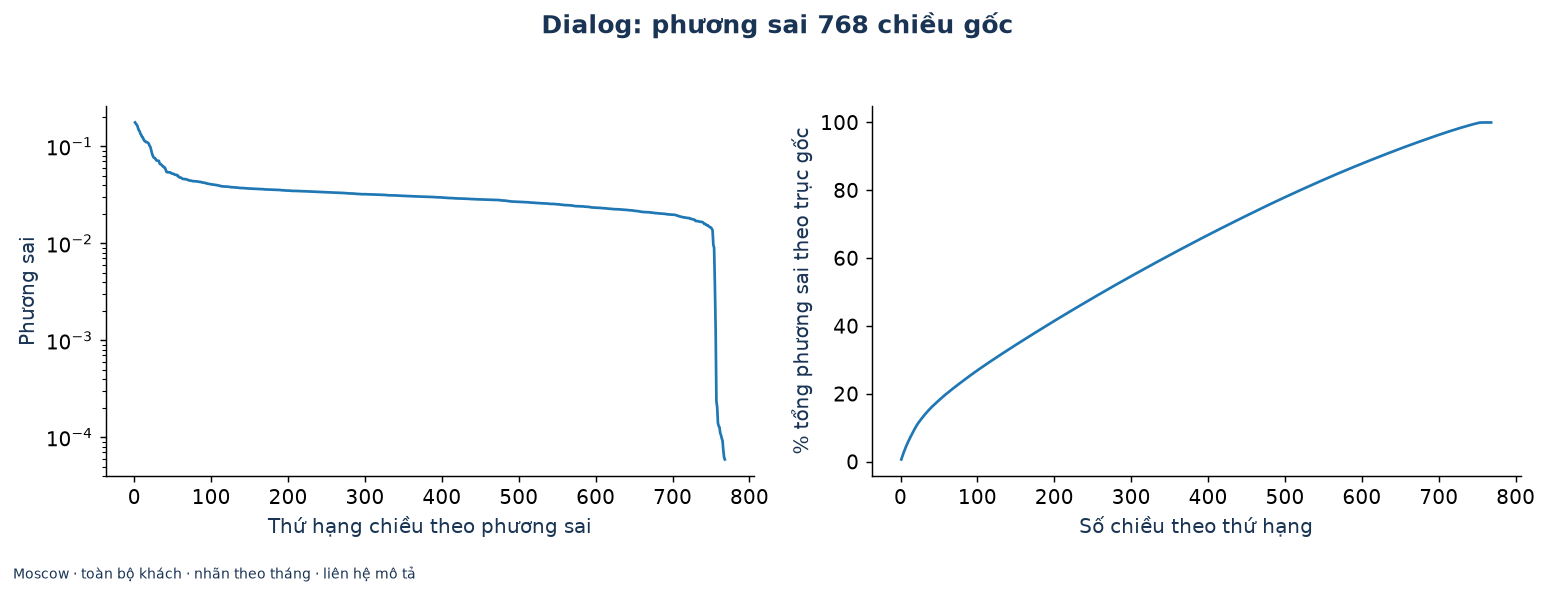

**outputs/eda_figures_moscow/dialog_exact_vector_duplicates.png**

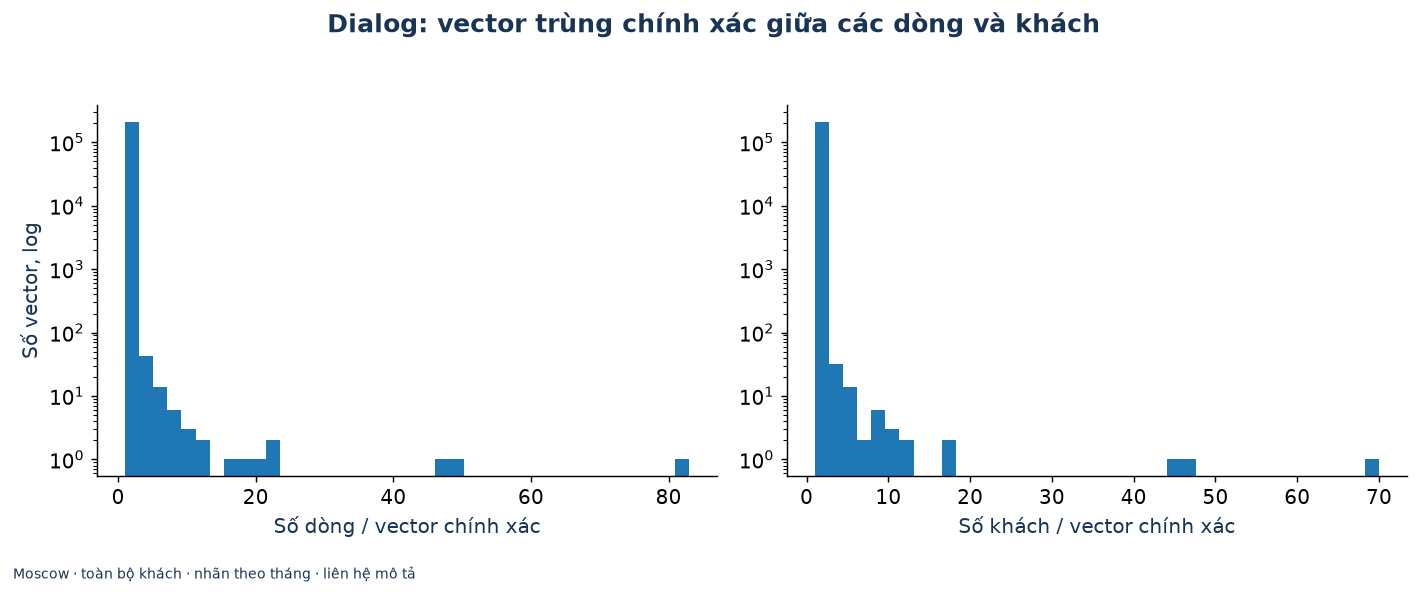

**outputs/eda_figures_moscow/dialog_fixed_reference_drift.png**

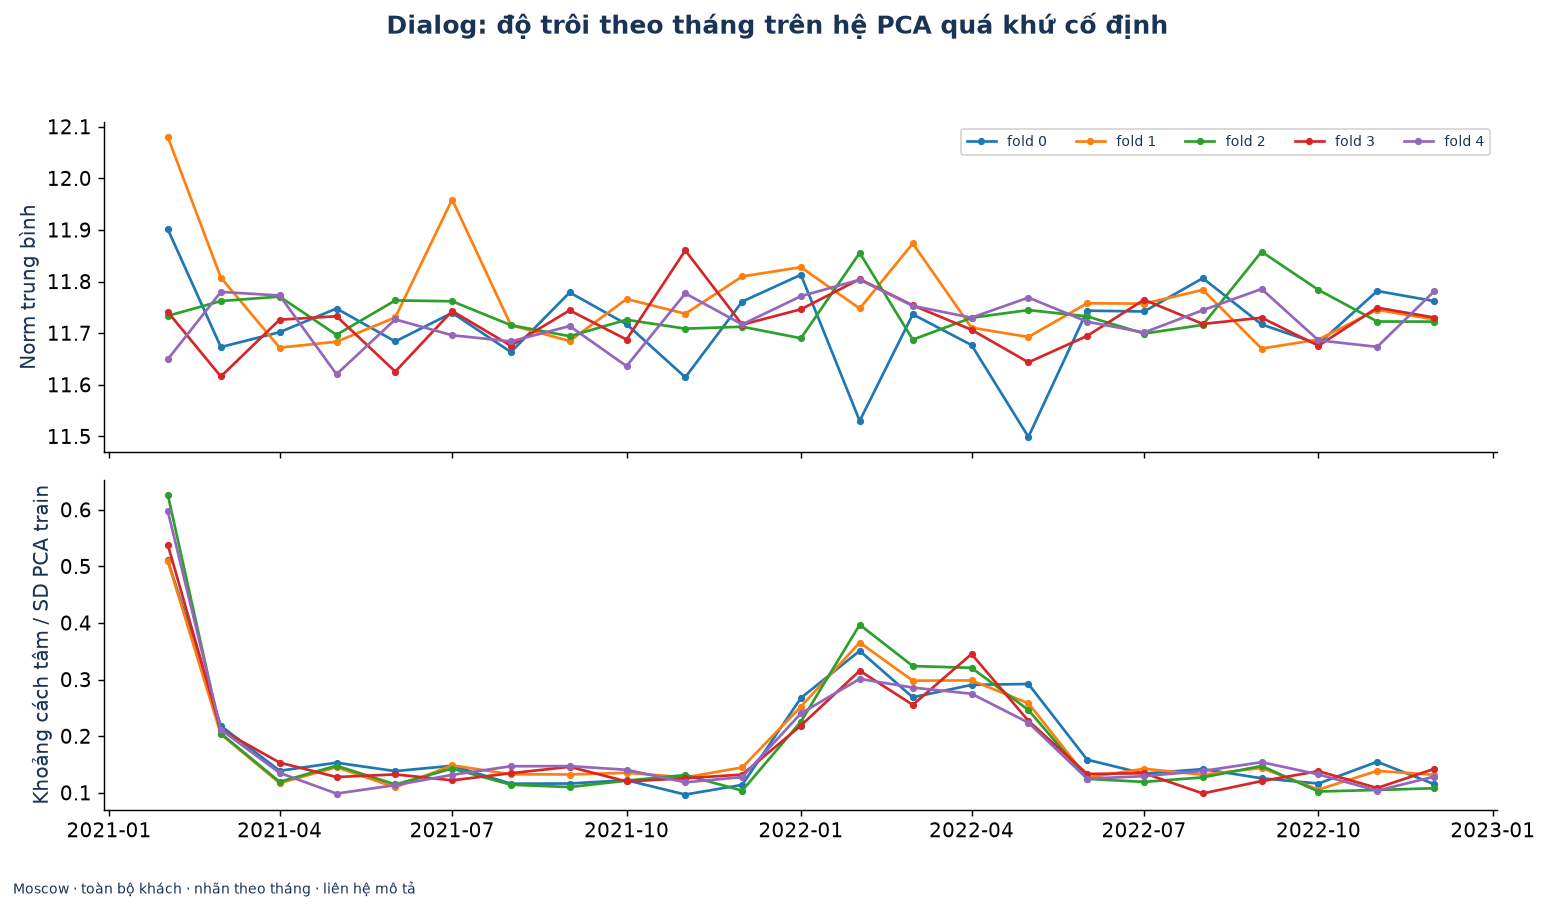

**outputs/eda_figures_moscow/dialog_pca_anisotropy.png**

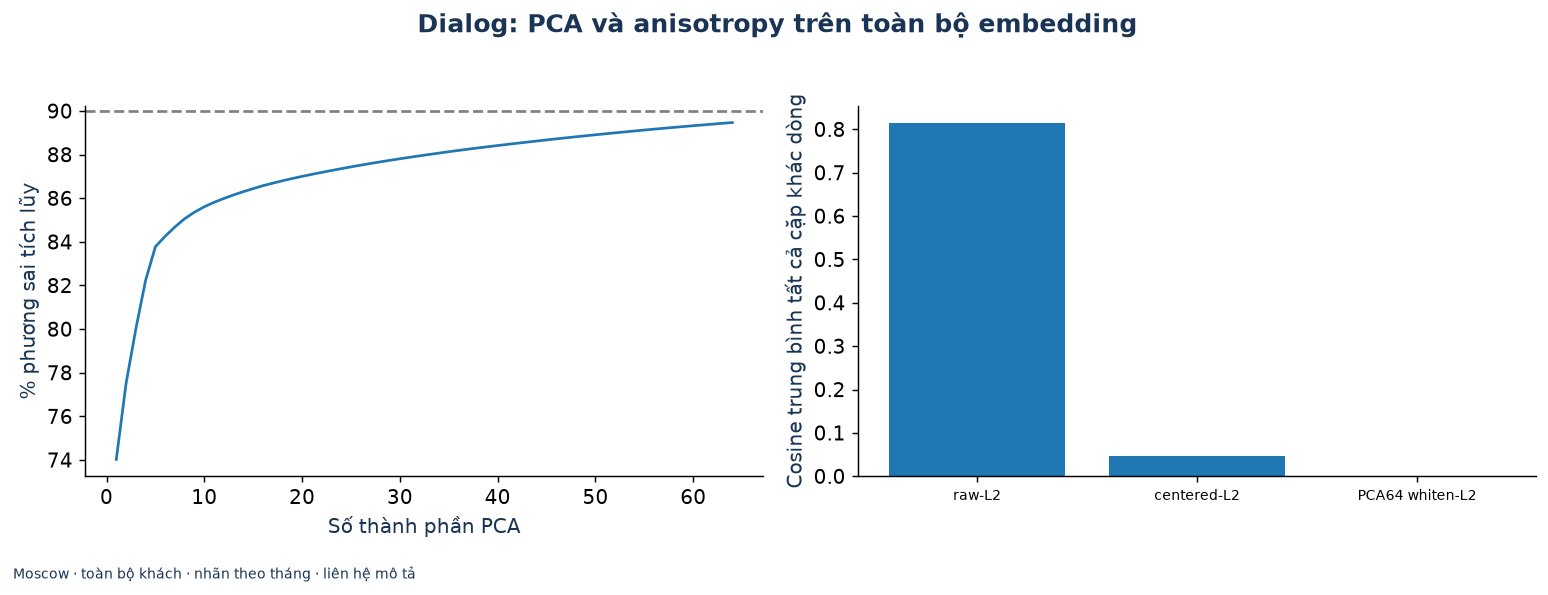

**outputs/eda_figures_moscow/dialog_dimension_variance.csv** — 5 dòng đầu

,dimension,mean,variance
0,0,0.291444,0.027841
1,1,-0.152668,0.025859
2,2,0.451410,0.022145
3,3,-0.266936,0.075783
4,4,-0.223786,0.017935


**outputs/eda_figures_moscow/dialog_exact_vector_duplicates.csv** — 5 dòng đầu

,vector_group,events,customers
0,0,1,1
1,1,1,1
2,2,1,1
3,3,1,1
4,4,1,1


**outputs/eda_figures_moscow/dialog_fixed_reference_drift.csv** — 5 dòng đầu

,month,fold,rows,customers,mean_norm,centroid_distance
0,2021-02-01,0,182,157,11.901357,0.510728
1,2021-02-01,1,171,154,12.080111,0.509203
2,2021-02-01,2,185,155,11.733463,0.626674
3,2021-02-01,3,171,150,11.741084,0.538167
4,2021-02-01,4,179,156,11.649310,0.597687


**outputs/eda_figures_moscow/dialog_pca_anisotropy.csv** — 5 dòng đầu

,components,cumulative_variance
0,1,0.740241
1,2,0.775069
2,3,0.800080
3,4,0.822383
4,5,0.837786


**outputs/eda_figures_moscow/figure_index.csv** — 5 dòng đầu

,figure,title,data,explanation
0,all_history_recency_by_purchase_month,Recency toàn lịch sử trước đầu tháng mua,all_history_recency_by_purchase_month.csv,all_history_recency_by_purchase_month.md
1,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
2,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
3,baseline_event_type_new_cells,event_type_new_cells: thay đổi so với nền của ...,baseline_event_type_new_cells.csv,baseline_event_type_new_cells.md
4,baseline_event_type_unique_cells,event_type_unique_cells: thay đổi so với nền c...,baseline_event_type_unique_cells.csv,baseline_event_type_unique_cells.md


File kết quả khác: `outputs/eda_figures_moscow/dialog_dimension_variance.md`, `outputs/eda_figures_moscow/dialog_embedding_metadata.parquet`, `outputs/eda_figures_moscow/dialog_exact_vector_duplicates.md`, `outputs/eda_figures_moscow/dialog_fixed_reference_drift.md`, `outputs/eda_figures_moscow/dialog_past_pca32_scores.npy`, `outputs/eda_figures_moscow/dialog_pca_anisotropy.md`, `outputs/eda_figures_moscow/execution_status.json`

In [11]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_dialog_geometry.py')

## Extend Eda Dialog Clusters

Nguồn: `src/scripts/extend_eda_dialog_clusters.py`. Chạy các ô của phần này theo thứ tự.

In [12]:
__file__ = str(ROOT / 'src/scripts/extend_eda_dialog_clusters.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [13]:
"""Past-only dialog clusters, deterministic fold stability and monthly composition."""
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import normalize
from sklearn.metrics import adjusted_rand_score
from complete_eda_figures_moscow import OUT, BASE, publish, INDEX


def model(k):
    return MiniBatchKMeans(n_clusters=k,random_state=42,n_init=5,batch_size=2048,max_iter=100)


def main():
    d=pd.read_parquet(OUT/'dialog_embedding_metadata.parquet')
    z=np.load(OUT/'dialog_past_pca32_scores.npy')
    cols=[f'pc{i}' for i in range(z.shape[1])]
    frame=pd.DataFrame(z,columns=cols)
    frame['client_id']=d.client_id.to_numpy();frame['fold']=d.fold.to_numpy();frame['month']=d.month.to_numpy()
    train=frame[frame.month<pd.Timestamp('2022-01-01')]
    customer=train.groupby(['client_id','fold'])[cols].mean().reset_index()
    x=normalize(customer[cols].to_numpy())
    rows=[];models={}
    for k in [2,4,8,16]:
        print('Dialog cluster k',k,flush=True)
        fit=model(k).fit(x);ref=fit.predict(x);models[k]=fit
        frac=np.bincount(ref,minlength=k)/len(ref)
        for fold in sorted(customer.fold.unique()):
            keep=customer.fold.to_numpy()!=fold
            alt=model(k).fit(x[keep]);pred=alt.predict(x)
            rows.append(dict(k=k,excluded_fold=int(fold),ari_all_reference_customers=adjusted_rand_score(ref,pred),
                             min_cluster_share=float(frac.min()),train_customers=len(x)))
    stable=pd.DataFrame(rows);agg=stable.groupby('k').agg(median_ari=('ari_all_reference_customers','median'),min_share=('min_cluster_share','min')).reset_index()
    eligible=agg[(agg.median_ari>=.7)&(agg.min_share>=.01)]
    if len(eligible):
        best=eligible.median_ari.max();chosen=int(eligible[eligible.median_ari>=best-.02].k.min());status='đạt ngưỡng ổn định đã khai báo'
    else:
        chosen=int(agg.sort_values(['median_ari','k'],ascending=[False,True]).iloc[0].k);status='chỉ thăm dò, không đạt ngưỡng ổn định'
    fit=models[chosen]
    stable.to_csv(OUT/'dialog_cluster_fold_stability.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    for fold,q in stable.groupby('excluded_fold'):axes[0].plot(q.k,q.ari_all_reference_customers,'o-',label=f'bỏ fold {fold}')
    axes[0].axhline(.7,color='gray',ls=':');axes[0].set_xlabel('k');axes[0].set_ylabel('ARI so với fit mọi fold');axes[0].legend(fontsize=7)
    axes[1].plot(agg.k,agg.min_share*100,'o-');axes[1].axhline(1,color='gray',ls=':');axes[1].set_ylabel('% cụm nhỏ nhất');axes[1].set_xlabel('k')
    publish('dialog_cluster_stability',fig,agg,'Dialog: độ ổn định cụm theo fold trên lịch sử trước 2022',
        'Dùng PCA32 đã fit sự kiện trước 01/01/2022 Moscow. Trung bình vector theo khách train rồi L2. '
        'MiniBatchKMeans k=2/4/8/16, seed42, n_init5, batch2048. Bỏ lần lượt mỗi fold, fit lại bốn fold, '
        'so ARI trên toàn khách tham chiếu. Chọn k nhỏ nhất trong 0,02 ARI so mức tốt nhất, cần median ARI≥0,7 và cụm nhỏ nhất≥1%.',
        'Đánh giá độ nhạy cấu trúc cụm khi thay khách dùng fit; không đo chất lượng ngữ nghĩa hoặc dự báo mua.',
        f'Chọn k={chosen}: {status}; bảng CSV giữ mọi k và fold, không chỉ phương án được chọn.',
        'ARI đánh giá trên tập tham chiếu gồm cả khách fit nên không phải đánh giá holdout; không thay thế bootstrap cụm. '
        'PCA fit mọi fold lịch sử; kiểm tra này đánh giá bước clustering, chưa đánh giá toàn pipeline khi bỏ fold.')
    monthly=frame.groupby(['client_id','month'])[cols].mean().reset_index()
    mx=normalize(monthly[cols].to_numpy());monthly['cluster']=fit.predict(mx)
    distance=np.linalg.norm(mx-fit.cluster_centers_[monthly.cluster.to_numpy()],axis=1)
    train_dist=np.linalg.norm(x-fit.cluster_centers_[fit.predict(x)],axis=1)
    threshold=float(np.quantile(train_dist,.99));monthly['far_from_reference']=distance>threshold
    monthly['distance']=distance
    labels=pd.read_parquet(BASE/'labels_any.parquet')
    ids=labels.client_id.unique();months=sorted(labels.month.unique())
    panel=pd.MultiIndex.from_product([ids,months],names=['client_id','month']).to_frame(index=False)
    panel=panel.merge(labels,on=['client_id','month'],validate='one_to_one')
    panel=panel.merge(monthly[['client_id','month','cluster','far_from_reference','distance']],on=['client_id','month'],how='left',validate='one_to_one')
    panel['group']=panel.cluster.map(lambda v: f'Cụm {int(v)}' if pd.notna(v) else 'Không thấy dialog')
    # Entire source unavailable in Jan2023, not an absence-of-dialog group.
    panel.loc[panel.month>=pd.Timestamp('2023-01-01'),'group']='Nguồn chưa quan sát'
    summary=panel.groupby(['month','group']).agg(customers=('client_id','size'),buyers=('y','sum')).reset_index()
    summary['purchase_rate']=summary.buyers/summary.customers
    assert summary.groupby('month').customers.sum().eq(100224).all()
    fig,axes=plt.subplots(2,1,figsize=(13,8))
    summary.pivot(index='month',columns='group',values='customers').fillna(0).div(100224).mul(100).plot.bar(stacked=True,ax=axes[0])
    summary.pivot(index='month',columns='group',values='purchase_rate').mul(100).plot(ax=axes[1],marker='o',ms=3)
    axes[0].set_ylabel('% toàn khách');axes[1].set_ylabel('% khách mua cùng tháng');axes[0].legend(fontsize=7,ncol=4);axes[1].legend(fontsize=7,ncol=4)
    publish('dialog_fixed_clusters_monthly_purchase',fig,summary,'Dialog: cơ cấu cụm cố định và mua cùng tháng',
        f'Dùng k={chosen} và hệ PCA/kmeans cố định từ lịch sử trước năm 2022. Mỗi khách–tháng có dialog lấy mean vector rồi L2; '
        'mỗi khách thuộc đúng một nhóm/tháng. Không dialog giữ riêng; 01/2023 ngoài nguồn giữ unavailable. '
        'Tỷ lệ mua dùng nhãn cùng tháng, không phải đánh giá tín hiệu đi trước.',
        'So cơ cấu biểu diễn và liên hệ đồng thời với tháng mua mà không đổi nhãn cụm qua thời gian.',
        f'Mỗi tháng phân hoạch đủ 100.224 khách; k={chosen} {status}. Nhóm cao có thể ít người; CSV có n và số mua.',
        'Nội dung không có text nên không đặt tên chủ đề. Mean tháng có thể gồm dialog sau thời điểm mua chưa biết trong tháng; '
        'không dùng tỷ lệ này như kết quả dự báo, chưa có bootstrap CI hoặc điều chỉnh TRX.')
    far=monthly.groupby('month').agg(customer_months=('client_id','size'),far_share=('far_from_reference','mean'),mean_distance=('distance','mean')).reset_index()
    fig,ax=plt.subplots(figsize=(12,4.5));ax.plot(far.month,far.far_share*100,'o-');ax.set_ylabel('% khách–tháng xa tâm tham chiếu');ax.grid(alpha=.2)
    publish('dialog_fixed_cluster_novelty',fig,far,'Dialog: khách–tháng xa cụm tham chiếu quá khứ',
        f'Khoảng cách mean-L2 khách–tháng đến tâm kmeans gần nhất; ngưỡng cố định P99 khoảng cách mean-L2 khách train={threshold:.5g}. '
        'Giữ nguyên PCA và tâm, không gọi nhãn KMeans là cụm mới.',
        'Đo mức ngoài phân phối tương đối so tập tham chiếu cố định, không khẳng định xuất hiện chủ đề mới.',
        f'Tỷ lệ xa tâm cao nhất {far.far_share.max()*100:.2f}%; CSV ghi n khách–tháng mỗi tháng.',
        'Ngưỡng fit mean toàn lịch sử khách train nhưng áp mean tháng nên có khác biệt độ dài chuỗi; '
        'đây là chỉ báo thăm dò, chưa kết luận drift thuần hoặc độ mới ngữ nghĩa.')
    panel.to_parquet(OUT/'dialog_fixed_cluster_label_panel.parquet',index=False)
    old=pd.read_csv(OUT/'figure_index.csv');idx=pd.concat([old,pd.DataFrame(INDEX)]).drop_duplicates('figure',keep='last');idx.to_csv(OUT/'figure_index.csv',index=False)
    statusj=json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'));statusj['done']+=['dialog_past_clusters_fold_stability','dialog_monthly_fixed_clusters_purchase','dialog_far_from_cluster_reference'];statusj['figures']=len(idx)
    (OUT/'execution_status.json').write_text(json.dumps(statusj,ensure_ascii=False,indent=2),encoding='utf-8')


if __name__=='__main__':main()

Dialog cluster k 2


Dialog cluster k 4


Dialog cluster k 8


Dialog cluster k 16


Saved dialog_cluster_stability


Saved dialog_fixed_clusters_monthly_purchase


Saved dialog_fixed_cluster_novelty


### Kết quả: `src/scripts/extend_eda_dialog_clusters.py`

**outputs/eda_figures_moscow/dialog_cluster_stability.png**

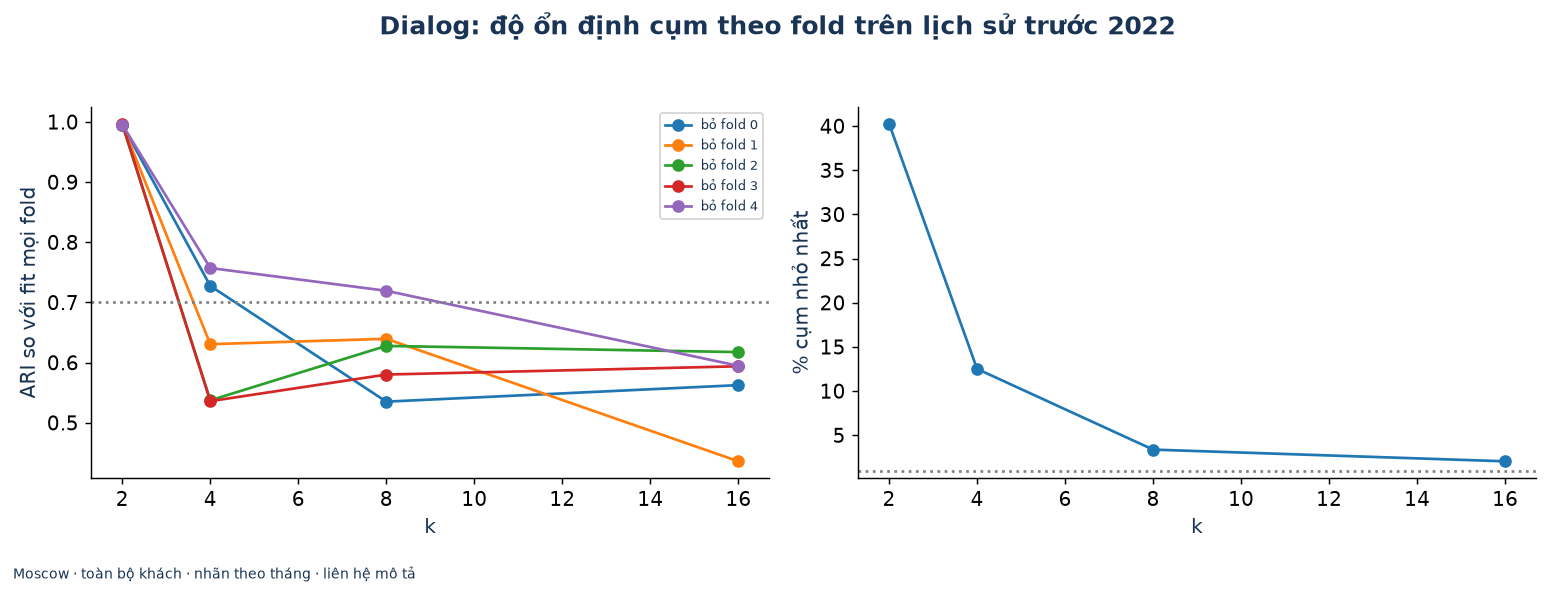

**outputs/eda_figures_moscow/dialog_fixed_cluster_novelty.png**

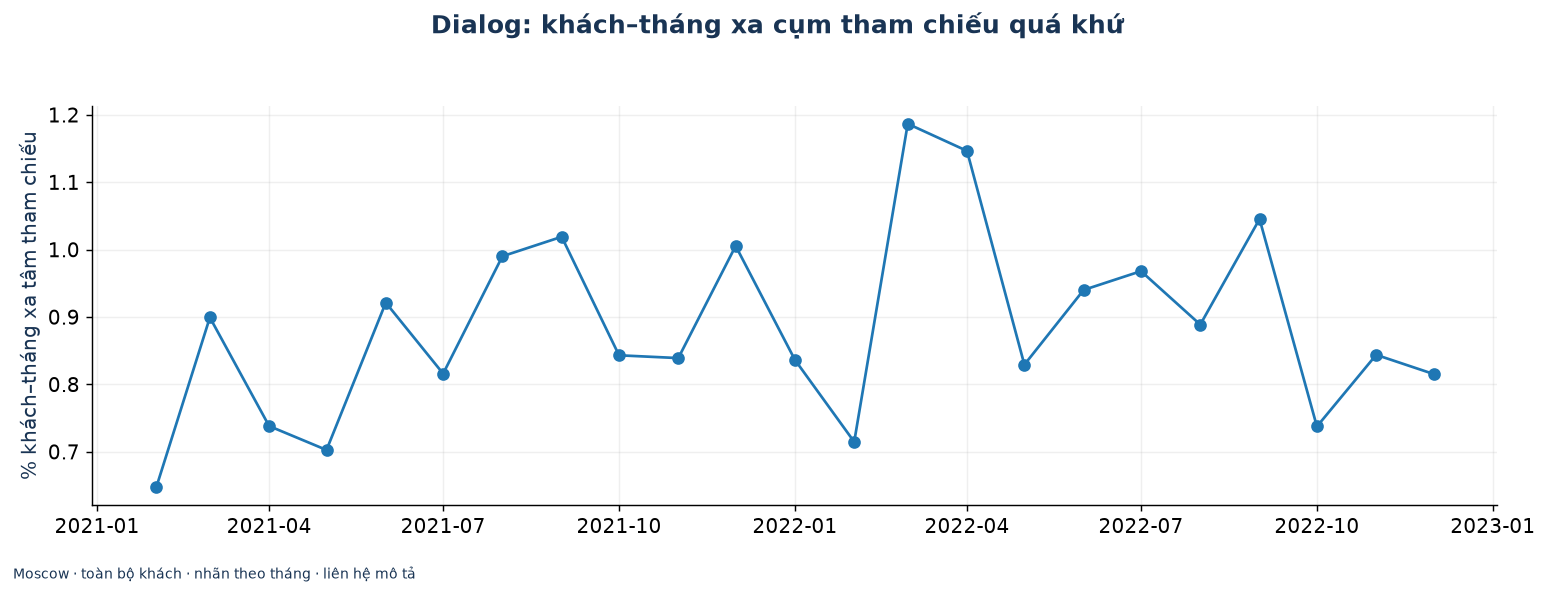

**outputs/eda_figures_moscow/dialog_fixed_clusters_monthly_purchase.png**

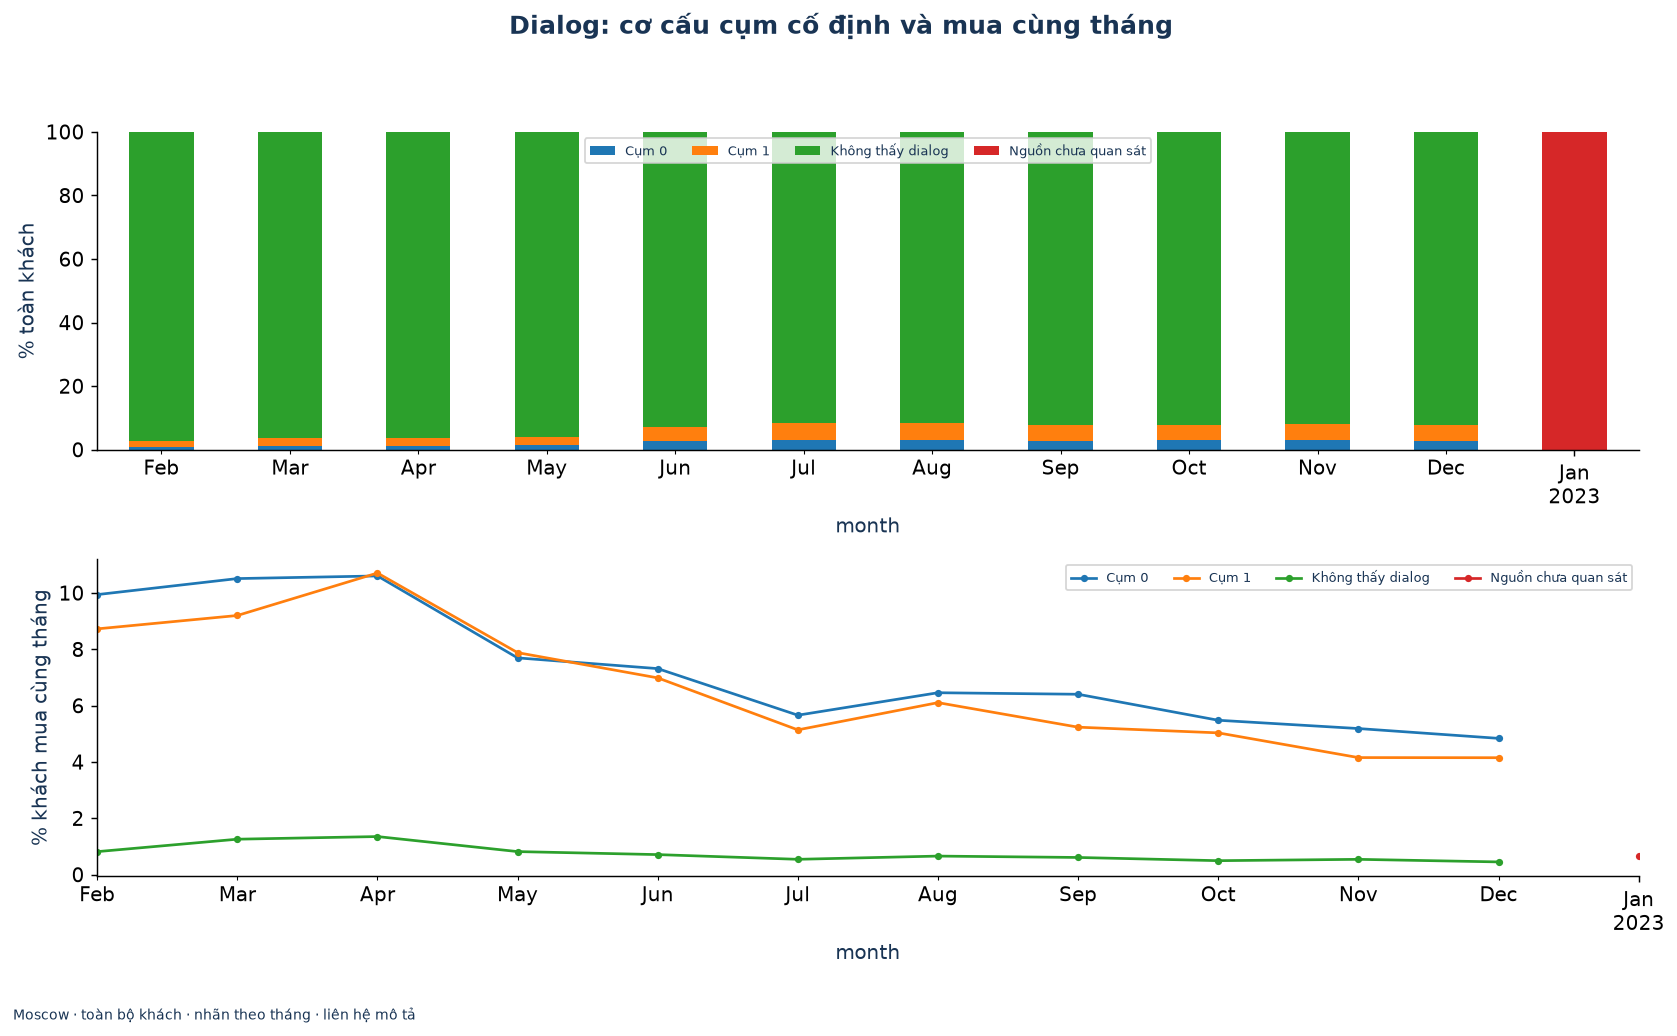

**outputs/eda_figures_moscow/dialog_cluster_fold_stability.csv** — 5 dòng đầu

,k,excluded_fold,ari_all_reference_customers,min_cluster_share,train_customers
0,2,0,0.995539,0.402878,28701
1,2,1,0.995539,0.402878,28701
2,2,2,0.995539,0.402878,28701
3,2,3,0.997350,0.402878,28701
4,2,4,0.995539,0.402878,28701


**outputs/eda_figures_moscow/dialog_cluster_stability.csv** — 5 dòng đầu

,k,median_ari,min_share
0,2,0.995539,0.402878
1,4,0.630672,0.125118
2,8,0.627849,0.033762
3,16,0.593978,0.020522


**outputs/eda_figures_moscow/dialog_fixed_cluster_novelty.csv** — 5 dòng đầu

,month,customer_months,far_share,mean_distance
0,2021-02-01,772,0.006477,0.588089
1,2021-03-01,4336,0.008994,0.575352
2,2021-04-01,5689,0.007383,0.581837
3,2021-05-01,5834,0.007028,0.578398
4,2021-06-01,5969,0.009214,0.577683


**outputs/eda_figures_moscow/dialog_fixed_clusters_monthly_purchase.csv** — 5 dòng đầu

,month,group,customers,buyers,purchase_rate
0,2022-02-01,Cụm 0,905,90,0.099448
1,2022-02-01,Cụm 1,1753,153,0.087279
2,2022-02-01,Không thấy dialog,97566,798,0.008179
3,2022-03-01,Cụm 0,1265,133,0.105138
4,2022-03-01,Cụm 1,2358,217,0.092027


**outputs/eda_figures_moscow/figure_index.csv** — 5 dòng đầu

,figure,title,data,explanation
0,all_history_recency_by_purchase_month,Recency toàn lịch sử trước đầu tháng mua,all_history_recency_by_purchase_month.csv,all_history_recency_by_purchase_month.md
1,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
2,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
3,baseline_event_type_new_cells,event_type_new_cells: thay đổi so với nền của ...,baseline_event_type_new_cells.csv,baseline_event_type_new_cells.md
4,baseline_event_type_unique_cells,event_type_unique_cells: thay đổi so với nền c...,baseline_event_type_unique_cells.csv,baseline_event_type_unique_cells.md


File kết quả khác: `outputs/eda_figures_moscow/dialog_cluster_stability.md`, `outputs/eda_figures_moscow/dialog_fixed_cluster_label_panel.parquet`, `outputs/eda_figures_moscow/dialog_fixed_cluster_novelty.md`, `outputs/eda_figures_moscow/dialog_fixed_clusters_monthly_purchase.md`, `outputs/eda_figures_moscow/execution_status.json`

In [14]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_dialog_clusters.py')